In [ ]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Generate 1000 records
n_samples = 1000

data = {
    'Loan_ID': [f'LP{str(i).zfill(4)}' for i in range(1, n_samples + 1)],
    'Age': np.random.randint(21, 66, size=n_samples),
    'Annual_Income': np.random.randint(25000, 150000, size=n_samples),
    'Loan_Amount': np.random.randint(5000, 450000, size=n_samples),
    'Credit_Score': np.random.randint(300, 851, size=n_samples),
    'Debt_to_Income_Ratio': np.round(np.random.uniform(0.1, 0.6, size=n_samples), 2)
}

# Calculate a realistic approval status based on credit score and debt-to-income
# High credit score and low DTI increase approval probability
score_factor = (data['Credit_Score'] - 300) / 550
dti_factor = 1.0 - data['Debt_to_Income_Ratio']
probability = (score_factor + dti_factor) / 2

# Map probabilities to Approved (1) or Rejected (0)
data['Loan_Status'] = np.where(probability + np.random.normal(0, 0.15, n_samples) > 0.5, 'Approved', 'Rejected')

# Create DataFrame
df_loans = pd.DataFrame(data)

# Display the first few rows of the dataset
print(f"Dataset Shape: {df_loans.shape}")
print(df_loans['Loan_Status'].value_counts())
df_loans.head()

Dataset Shape: (1000, 7)
Loan_Status
Approved    635
Rejected    365
Name: count, dtype: int64


,Loan_ID,Age,Annual_Income,Loan_Amount,Credit_Score,Debt_to_Income_Ratio,Loan_Status
0,LP0001,59,48930,196184,535,0.55,Rejected
1,LP0002,49,25077,107471,502,0.10,Rejected
2,LP0003,35,130881,259225,555,0.55,Approved
3,LP0004,63,45611,162661,534,0.18,Approved
4,LP0005,28,41984,166087,644,0.60,Rejected


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Define features (X) and target (y)
features = ['Age', 'Annual_Income', 'Loan_Amount', 'Credit_Score', 'Debt_to_Income_Ratio']
X = df_loans[features]
y = df_loans['Loan_Status'].map({'Approved': 1, 'Rejected': 0}) # Encode target variable

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the features for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the Logistic Regression Model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test_scaled)

# Print evaluation metrics
print("=== Model Evaluation ===")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))


=== Model Evaluation ===
Accuracy Score: 0.8000

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.75      0.68      0.71        73
    Approved       0.83      0.87      0.85       127

    accuracy                           0.80       200
   macro avg       0.79      0.78      0.78       200
weighted avg       0.80      0.80      0.80       200



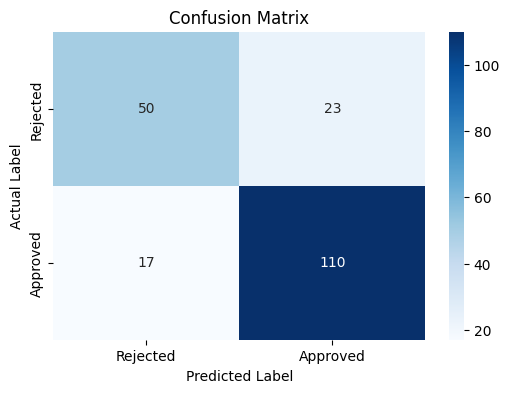

=== Feature Coefficients (Importance) ===


,Feature,Coefficient
3,Credit_Score,1.578828
2,Loan_Amount,0.003475
0,Age,-0.060907
1,Annual_Income,-0.107486
4,Debt_to_Income_Ratio,-0.847158


In [ ]:
# Plot the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Rejected', 'Approved'], yticklabels=['Rejected', 'Approved'])
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# Display the coefficients to see feature importance
coefficients = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("=== Feature Coefficients (Importance) ===")
display(coefficients)

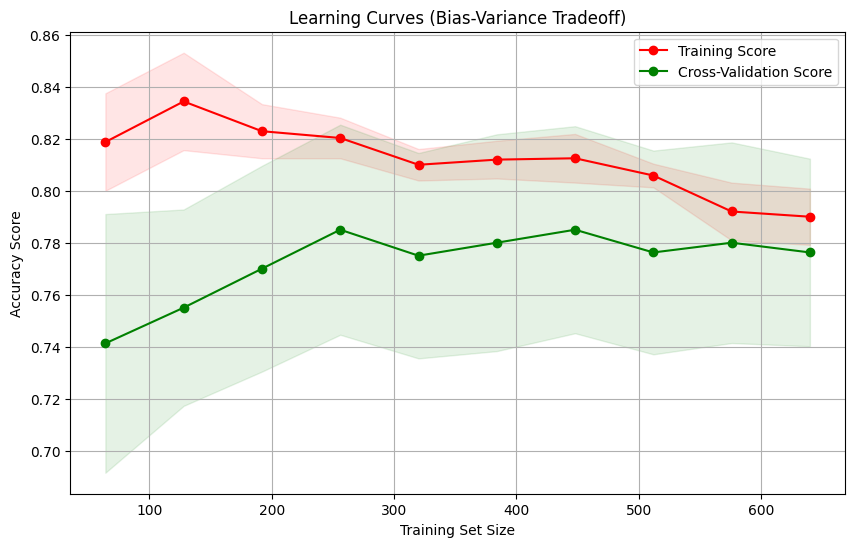

In [ ]:
from sklearn.model_selection import learning_curve

# Calculate learning curves
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,
    X=X_train_scaled,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Calculate mean and standard deviation of training and test scores
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot the learning curve
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='r', label='Training Score')
plt.plot(train_sizes, test_mean, 'o-', color='g', label='Cross-Validation Score')

# Add fill area to show variance/uncertainty
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='r')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color='g')

plt.title('Learning Curves (Bias-Variance Tradeoff)')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy Score')
plt.legend(loc='best')
plt.grid(True)
plt.show()

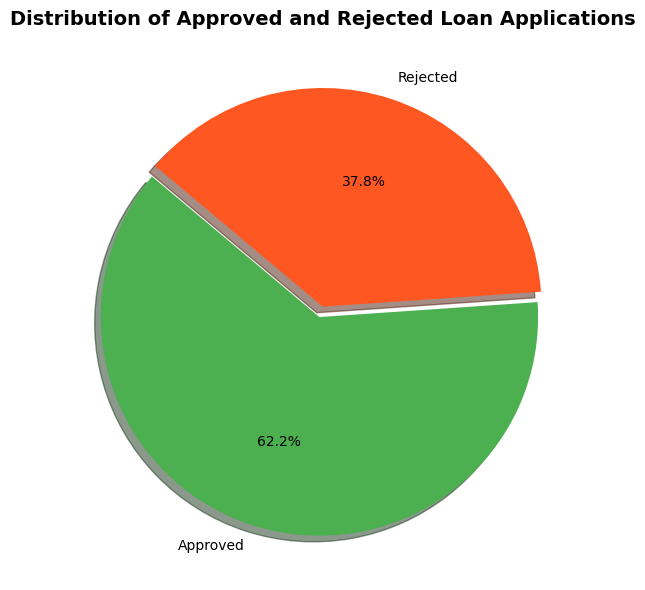

In [7]:
import matplotlib.pyplot as plt

# Count the occurrences of each loan status category in the new dataset
status_counts = df_loans['Loan_Status'].value_counts()

# Define colors and explode properties for visual appeal
colors = ['#4CAF50', '#FF5722']
explode = (0.05, 0) if len(status_counts) > 1 else (0,)

# Create a pie chart
plt.figure(figsize=(8, 6))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors[:len(status_counts)],
    explode=explode,
    shadow=True
)

plt.title('Distribution of Approved and Rejected Loan Applications', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [8]:
import ipywidgets as widgets
from IPython.display import display, HTML

# Create input widgets for the features
age_widget = widgets.IntSlider(value=35, min=21, max=65, step=1, description='Age:')
income_widget = widgets.IntSlider(value=75000, min=25000, max=150000, step=1000, description='Income ($):')
loan_widget = widgets.IntSlider(value=150000, min=5000, max=450000, step=1000, description='Loan ($):')
credit_widget = widgets.IntSlider(value=650, min=300, max=850, step=1, description='Credit Score:')
dti_widget = widgets.FloatSlider(value=0.35, min=0.10, max=0.60, step=0.01, description='DTI Ratio:')

predict_button = widgets.Button(description="Predict Loan Status", button_style='success')
output_area = widgets.Output()

def make_prediction(b):
    with output_area:
        output_area.clear_output()
        # Prepare input data
        custom_data = pd.DataFrame([{
            'Age': age_widget.value,
            'Annual_Income': income_widget.value,
            'Loan_Amount': loan_widget.value,
            'Credit_Score': credit_widget.value,
            'Debt_to_Income_Ratio': dti_widget.value
        }])

        # Scale features using the trained scaler
        custom_data_scaled = scaler.transform(custom_data)

        # Get model prediction and probability
        prediction = model.predict(custom_data_scaled)[0]
        probability = model.predict_proba(custom_data_scaled)[0][1]

        # Output visual result
        if prediction == 1:
            status_html = f"<div style='padding: 10px; background-color: #d4edda; color: #155724; border-radius: 5px; font-weight: bold;'>Status: Approved (Probability: {probability:.2%})</div>"
        else:
            status_html = f"<div style='padding: 10px; background-color: #f8d7da; color: #721c24; border-radius: 5px; font-weight: bold;'>Status: Rejected (Probability of Approval: {probability:.2%})</div>"

        display(HTML(status_html))

predict_button.on_click(make_prediction)

# Layout and display widgets
ui = widgets.VBox([
    widgets.HTML("<h3>Enter Custom Loan Application Details</h3>"),
    age_widget,
    income_widget,
    loan_widget,
    credit_widget,
    dti_widget,
    widgets.Label(""),
    predict_button,
    widgets.Label(""),
    output_area
])

display(ui)

### Define and Load the New Dataset
Below, we will define a new dataset. Feel free to modify the parameters or logic to better suit the scenario you want to simulate!

In [6]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(101)

n_samples = 1500

# Create a new dataset scenario with different distributions or additional columns
new_data = {
    'Loan_ID': [f'LP{str(i).zfill(4)}' for i in range(1, n_samples + 1)],
    'Age': np.random.randint(18, 70, size=n_samples),
    'Annual_Income': np.random.randint(30000, 200000, size=n_samples),
    'Loan_Amount': np.random.randint(10000, 600000, size=n_samples),
    'Credit_Score': np.random.randint(350, 850, size=n_samples),
    'Debt_to_Income_Ratio': np.round(np.random.uniform(0.05, 0.70, size=n_samples), 2)
}

# Updated decision logic for loan approval
score_factor = (new_data['Credit_Score'] - 350) / 500
dti_factor = 1.0 - new_data['Debt_to_Income_Ratio']
income_to_loan_ratio = new_data['Annual_Income'] / new_data['Loan_Amount']
income_factor = np.clip(income_to_loan_ratio / 2.0, 0, 1)  # Normalize ratio influence

probability = (score_factor * 0.4) + (dti_factor * 0.4) + (income_factor * 0.2)

# Map probabilities with noise to Approved or Rejected
new_data['Loan_Status'] = np.where(probability + np.random.normal(0, 0.1, n_samples) > 0.45, 'Approved', 'Rejected')

# Create DataFrame
df_loans = pd.DataFrame(new_data)

print(f"New Dataset Shape: {df_loans.shape}")
print(df_loans['Loan_Status'].value_counts())
display(df_loans.head())

New Dataset Shape: (1500, 7)
Loan_Status
Approved    933
Rejected    567
Name: count, dtype: int64


,Loan_ID,Age,Annual_Income,Loan_Amount,Credit_Score,Debt_to_Income_Ratio,Loan_Status
0,LP0001,49,187149,233394,527,0.23,Approved
1,LP0002,29,177664,475522,477,0.34,Rejected
2,LP0003,35,187234,136739,422,0.42,Rejected
3,LP0004,24,163391,51195,615,0.27,Approved
4,LP0005,41,174063,71933,625,0.55,Approved


### Bias vs. Variance Analysis:
- **High Bias (Underfitting):** If both the training score and validation score are low and close to each other, the model is too simple to capture the underlying pattern.
- **High Variance (Overfitting):** If there is a large gap between the high training score and the lower validation score, the model is overfitting to the training data.
- **Good Balance:** In this chart, we can observe where the two curves converge, indicating how well the model generalizes as more training data is provided.